### Visualize held-out feature dimension CCGP, pre-stimulus
Runs of `scripts/pseudo_decoding/belief_partitions/dim_ccgp_heldout_feat_beliefs.py`, proposal in `claude_notes/dimension_ccgp_heldout_features_proposal.md`.

For each pair of dimensions (A, B), sessions contribute 3 features per dimension (roles A1-A3, B1-B3), balanced in trials. Each fold trains a decoder, labelled by dimension, on two roles per dimension and tests it on the held-out pair (A_k, B_k).
- **train**: held-out accuracy on the training roles
- **CCGP**: accuracy on all trials of the held-out pair

Shown for all units, and for `dim_pair_99th_pre_stim_window_filter_drift` preselected units. Shuffles are session permuted. Error bands are SE over dimension pairs x folds x splits. Significance bars are the stored p values of `compute_p_vals_for_dim_ccgp_heldout.py`, true vs shuffle per bin (thin p < 0.05, medium p < 0.01, thick p < 0.001).

Also for `dim_pair_fold_99th_pre_stim_window_filter_drift` units, selected per fold on that fold's training features only, so the held-out pair never enters selection; the `dim pair units` panel's selection used all six features, held-out pairs included.

In [2]:
%load_ext autoreload
%autoreload 2

import os
import argparse
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

import utils.visualization_utils as visualization_utils
from scripts.pseudo_decoding.belief_partitions.belief_partition_configs import *
import scripts.pseudo_decoding.belief_partitions.belief_partitions_io as belief_partitions_io
from scripts.pseudo_decoding.belief_partitions.generate_dim_heldout_sessions import DIM_PAIRS_PATH

In [3]:
dim_pairs = pd.read_pickle(DIM_PAIRS_PATH)
UNIT_SETS = {
    "all units": None,
    "dim pair units": "dim_pair_99th_pre_stim_window_filter_drift",
    # selected per fold on the training features only (dim_pair_anova.py --per_fold)
    "dim pair fold units": "dim_pair_fold_99th_pre_stim_window_filter_drift",
}

all_res, all_p_vals = [], []
for unit_set, sig_unit_level in UNIT_SETS.items():
    args = argparse.Namespace(
        **BeliefPartitionConfigs()._asdict()
    )
    args.subject = "both"
    args.trial_event = "StimOnset"
    args.mode = "dim_ccgp_heldout"
    args.sig_unit_level = sig_unit_level
    args.base_output_path = "/data/patrick_res/dim_ccgp_heldout"

    res = belief_partitions_io.read_dim_ccgp_heldout_results(args, dim_pairs, num_shuffles=10)
    res["unit_set"] = unit_set
    all_res.append(res)
    p_vals = pd.read_pickle(os.path.join(belief_partitions_io.get_dir_name(args, make_dir=False), "dim_ccgp_heldout_p_vals.pickle"))
    p_vals["unit_set"] = unit_set
    all_p_vals.append(p_vals)
res = pd.concat(all_res, ignore_index=True)
p_vals = pd.concat(all_p_vals, ignore_index=True)

# population per run, true vs shuffle
res.groupby(["unit_set", "dim_a", "dim_b", "fold", "shuffle_type"])[["n_sessions", "n_units", "n_dropped_sessions"]].agg(["min", "max"])

n_sessions     n_units  \
                                                             min max     min   
unit_set            dim_a   dim_b   fold shuffle_type                          
all units           Color   Pattern 0    shuffle              20  20     473   
                                         true                 20  20     473   
                                    1    shuffle              20  20     473   
                                         true                 20  20     473   
                                    2    shuffle              20  20     473   
                                         true                 20  20     473   
                            Shape   0    shuffle              16  16     381   
                                         true                 16  16     381   
                                    1    shuffle              16  16     381   
                                         true                 16  16     381   
                                    2    shuffle              16  16     381   
                                         true                 16  16     381   
                    Pattern Shape   0    shuffle              16  16     386   
                                         true                 16  16     386   
                                    1    shuffle              16  16     386   
                                         true                 16  16     386   
                                    2    shuffle              16  16     386   
                                         true                 16  16     386   
dim pair fold units Color   Pattern 0    shuffle              14  14      27   
                                         true                 14  14      27   
                                    1    shuffle              15  15      31   
                                         true                 15  15      31   
                                    2    shuffle              16  16      32   
                                         true                 16  16      32   
                            Shape   0    shuffle              15  15      37   
                                         true                 15  15      37   
                                    1    shuffle              12  12      23   
                                         true                 12  12      23   
                                    2    shuffle              12  12      29   
                                         true                 12  12      29   
                    Pattern Shape   0    shuffle              16  16      32   
                                         true                 16  16      32   
                                    1    shuffle              11  11      21   
                                         true                 11  11      21   
                                    2    shuffle              12  12      31   
                                         true                 12  12      31   
dim pair units      Color   Pattern 0    shuffle              15  15      33   
                                         true                 15  15      33   
                                    1    shuffle              15  15      33   
                                         true                 15  15      33   
                                    2    shuffle              15  15      33   
                                         true                 15  15      33   
                            Shape   0    shuffle              13  13      34   
                                         true                 13  13      34   
                                    1    shuffle              13  13      34   
                                         true                 13  13      34   
                                    2    shuffle              13  13      34   
                                         true         

In [4]:
# long format, one row per (run row, measure), with the earlier CCGP figures' colors
MEASURE_TO_DISPLAY = {"train_acc": "train", "ccgp_acc": "CCGP"}
COND_TO_COLOR = {
    "train": "#1b9e77",
    "train shuffle": "#b3e2cd",
    "CCGP": "#d95f02",
    "CCGP shuffle": "#fdcdac",
}
long_res = res.melt(
    id_vars=["unit_set", "dim_a", "dim_b", "fold", "split_idx", "shuffle_idx", "shuffle_type", "Time", "TimeIdx"],
    value_vars=list(MEASURE_TO_DISPLAY), var_name="measure", value_name="Accuracy",
)
long_res["condition"] = long_res.measure.map(MEASURE_TO_DISPLAY) + np.where(long_res.shuffle_type == "shuffle", " shuffle", "")

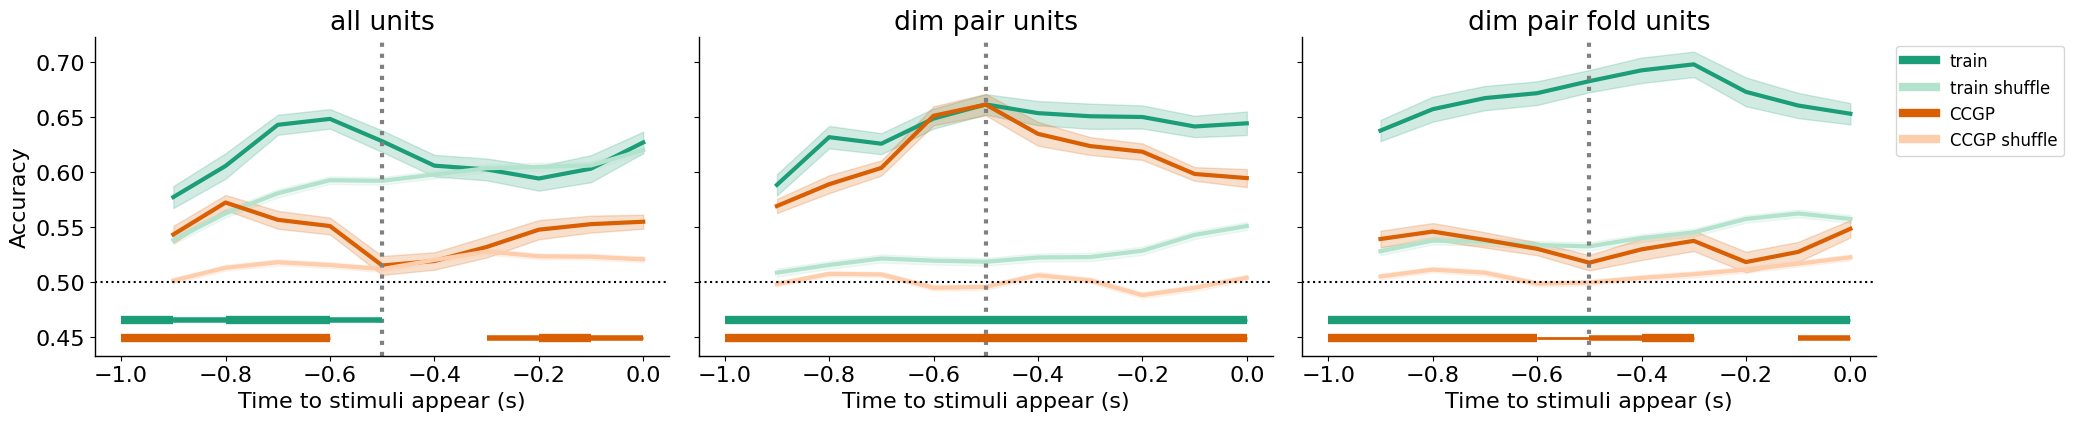

In [5]:
plt.rcParams.update({'font.size': 16})
fig, axs = plt.subplots(1, len(UNIT_SETS), figsize=(21, 4.5), sharey=True)
for ax, unit_set in zip(axs, UNIT_SETS):
    sns.lineplot(
        long_res[long_res.unit_set == unit_set], x="Time", y="Accuracy", hue="condition", hue_order=list(COND_TO_COLOR),
        palette=COND_TO_COLOR, linewidth=3, errorbar="se", ax=ax, legend=(ax is axs[-1]),
    )
    ax.axhline(0.5, linestyle="dotted", color="black")
    ax.axvline(-.5, color='grey', linestyle='dotted', linewidth=3)
    ax.set_title(unit_set)
    ax.set_xlabel("Time to stimuli appear (s)")
    ax.set_ylabel("Accuracy")

# significance bars below the lines, one row per measure, in that measure's color
y_min, y_max = axs[0].get_ylim()
interval = (y_max - y_min) / 15
for ax, unit_set in zip(axs, UNIT_SETS):
    unit_p_vals = p_vals[p_vals.unit_set == unit_set]
    for i, (measure, display) in enumerate(MEASURE_TO_DISPLAY.items()):
        visualization_utils.plot_sig_bars(unit_p_vals[unit_p_vals.measure == measure], y_min - interval * (i + 0.5), ax, color=COND_TO_COLOR[display])
axs[0].set_ylim(bottom=y_min - interval * (len(MEASURE_TO_DISPLAY) + 0.5))

legend = axs[-1].legend(fontsize=12, loc="upper left", bbox_to_anchor=(1.02, 1))
for line in legend.get_lines():
    line.set_linewidth(6)
visualization_utils.format_plot(list(axs))
fig.tight_layout()

In [6]:
# mean accuracy per bin and condition, next to the p values
tables = []
for unit_set in UNIT_SETS:
    means = long_res[long_res.unit_set == unit_set].groupby(["Time", "condition"]).Accuracy.mean().unstack()[list(COND_TO_COLOR)]
    ps = p_vals[p_vals.unit_set == unit_set].pivot(index="Time", columns="measure", values="p").rename(columns=lambda m: f"p {MEASURE_TO_DISPLAY[m]}")
    tables.append(pd.concat({unit_set: means.join(ps)}, axis=1))
pd.concat(tables, axis=1).round(3)

all units                                                   \
         train train shuffle   CCGP CCGP shuffle p CCGP p train   
Time                                                              
-0.9     0.577         0.538  0.543        0.501  0.000   0.000   
-0.8     0.605         0.562  0.572        0.513  0.000   0.001   
-0.7     0.643         0.581  0.557        0.518  0.000   0.000   
-0.6     0.648         0.593  0.551        0.515  0.000   0.000   
-0.5     0.628         0.592  0.515        0.512  0.388   0.001   
-0.4     0.606         0.598  0.519        0.520  0.553   0.232   
-0.3     0.602         0.603  0.532        0.528  0.292   0.525   
-0.2     0.594         0.605  0.548        0.523  0.005   0.803   
-0.1     0.603         0.606  0.553        0.523  0.000   0.565   
 0.0     0.627         0.620  0.555        0.521  0.001   0.304   

     dim pair units                                                   \
              train train shuffle   CCGP CCGP shuffle p CCGP p train   
Time                                                                   
-0.9          0.588         0.509  0.569        0.498    0.0     0.0   
-0.8          0.632         0.516  0.589        0.508    0.0     0.0   
-0.7          0.626         0.521  0.604        0.507    0.0     0.0   
-0.6          0.648         0.519  0.651        0.495    0.0     0.0   
-0.5          0.661         0.519  0.661        0.496    0.0     0.0   
-0.4          0.653         0.522  0.635        0.506    0.0     0.0   
-0.3          0.651         0.523  0.624        0.502    0.0     0.0   
-0.2          0.650         0.529  0.618        0.488    0.0     0.0   
-0.1          0.641         0.543  0.598        0.495    0.0     0.0   
 0.0          0.644         0.551  0.594        0.504    0.0     0.0   

     dim pair fold units                                                   
                   train train shuffle   CCGP CCGP shuffle p CCGP p train  
Time                                                                       
-0.9               0.638         0.528  0.539        0.505  0.000     0.0  
-0.8               0.657         0.538  0.546        0.511  0.000     0.0  
-0.7               0.667         0.537  0.538        0.509  0.000     0.0  
-0.6               0.672         0.534  0.530        0.499  0.000     0.0  
-0.5               0.682         0.532  0.518        0.500  0.015     0.0  
-0.4               0.692         0.540  0.530        0.504  0.003     0.0  
-0.3               0.698         0.545  0.537        0.507  0.000     0.0  
-0.2               0.673         0.557  0.518        0.511  0.236     0.0  
-0.1               0.660         0.562  0.527        0.517  0.114     0.0  
 0.0               0.653         0.557  0.548        0.523  0.002     0.0

In [7]:
# true minus mean shuffle per dimension pair, averaged over bins and folds
gaps = res.groupby(["unit_set", "dim_a", "dim_b", "shuffle_type"])[["train_acc", "ccgp_acc"]].mean().unstack("shuffle_type")
gaps = pd.DataFrame({
    "train gap": gaps[("train_acc", "true")] - gaps[("train_acc", "shuffle")],
    "CCGP gap": gaps[("ccgp_acc", "true")] - gaps[("ccgp_acc", "shuffle")],
})
gaps.round(4)

train gap  CCGP gap
unit_set            dim_a   dim_b                       
all units           Color   Pattern     0.0292    0.0662
                            Shape       0.0059   -0.0141
                    Pattern Shape       0.0357    0.0287
dim pair fold units Color   Pattern     0.1564    0.0665
                            Shape       0.1286    0.0126
                    Pattern Shape       0.0932   -0.0048
dim pair units      Color   Pattern     0.1527    0.1555
                            Shape       0.0952    0.0885
                    Pattern Shape       0.0952    0.0995

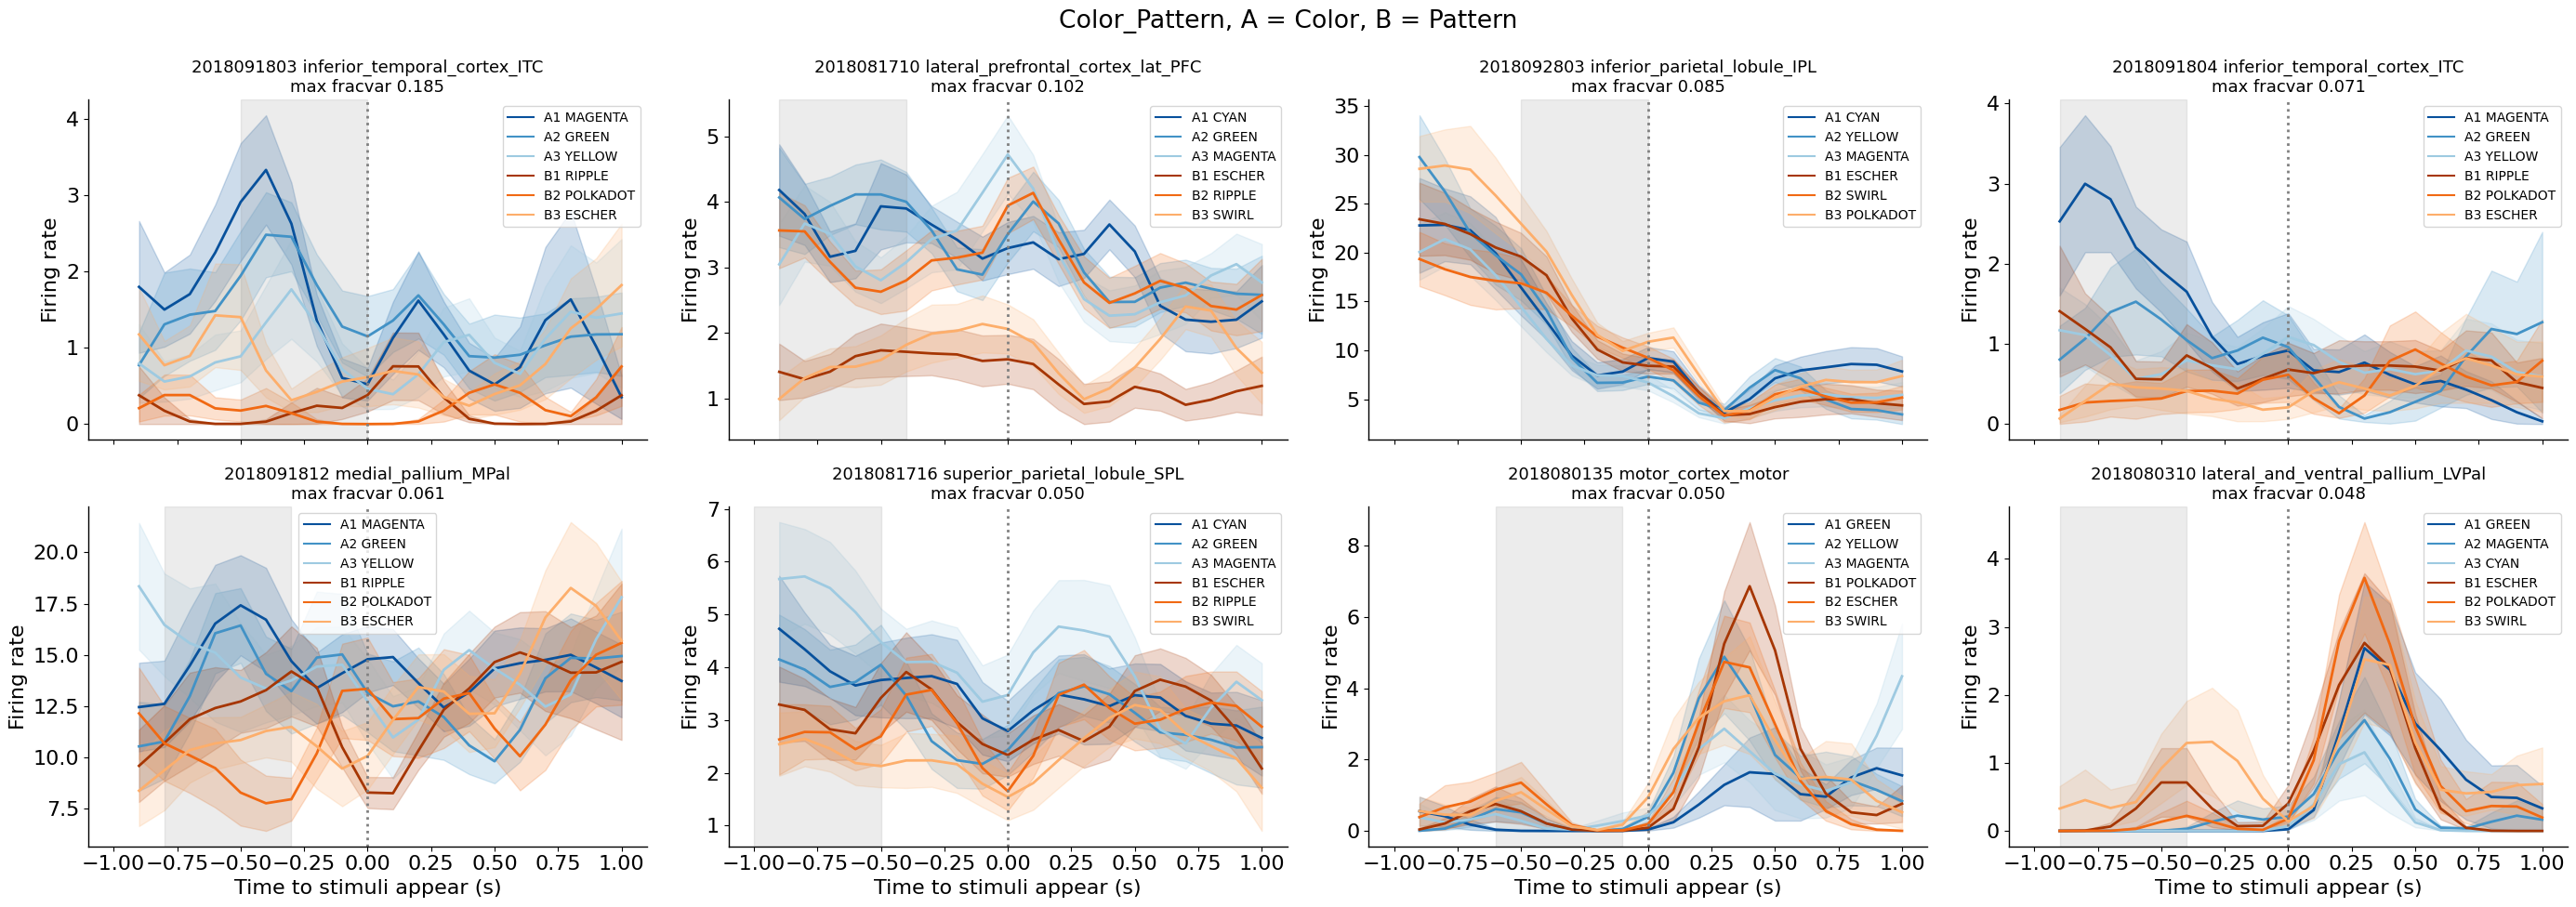

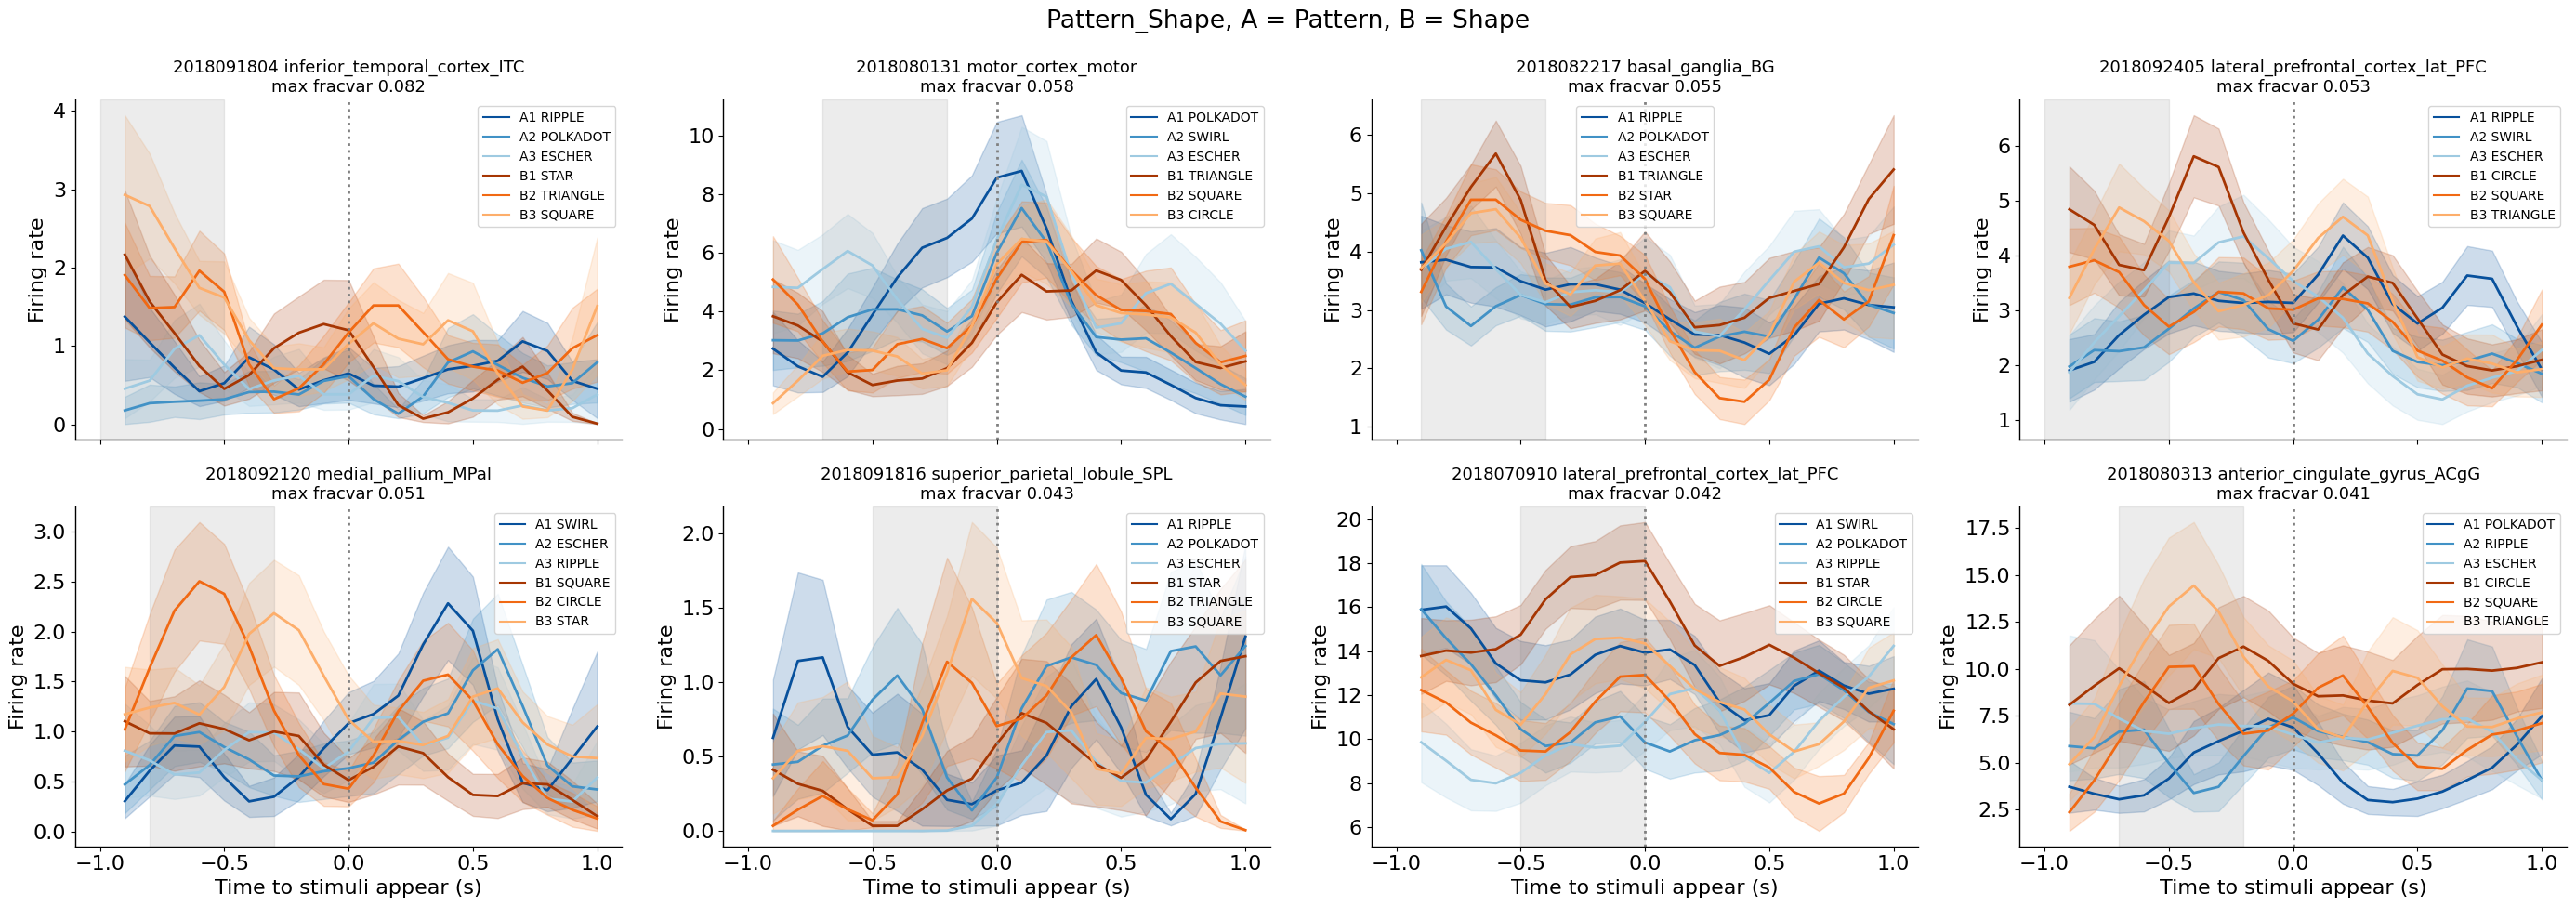

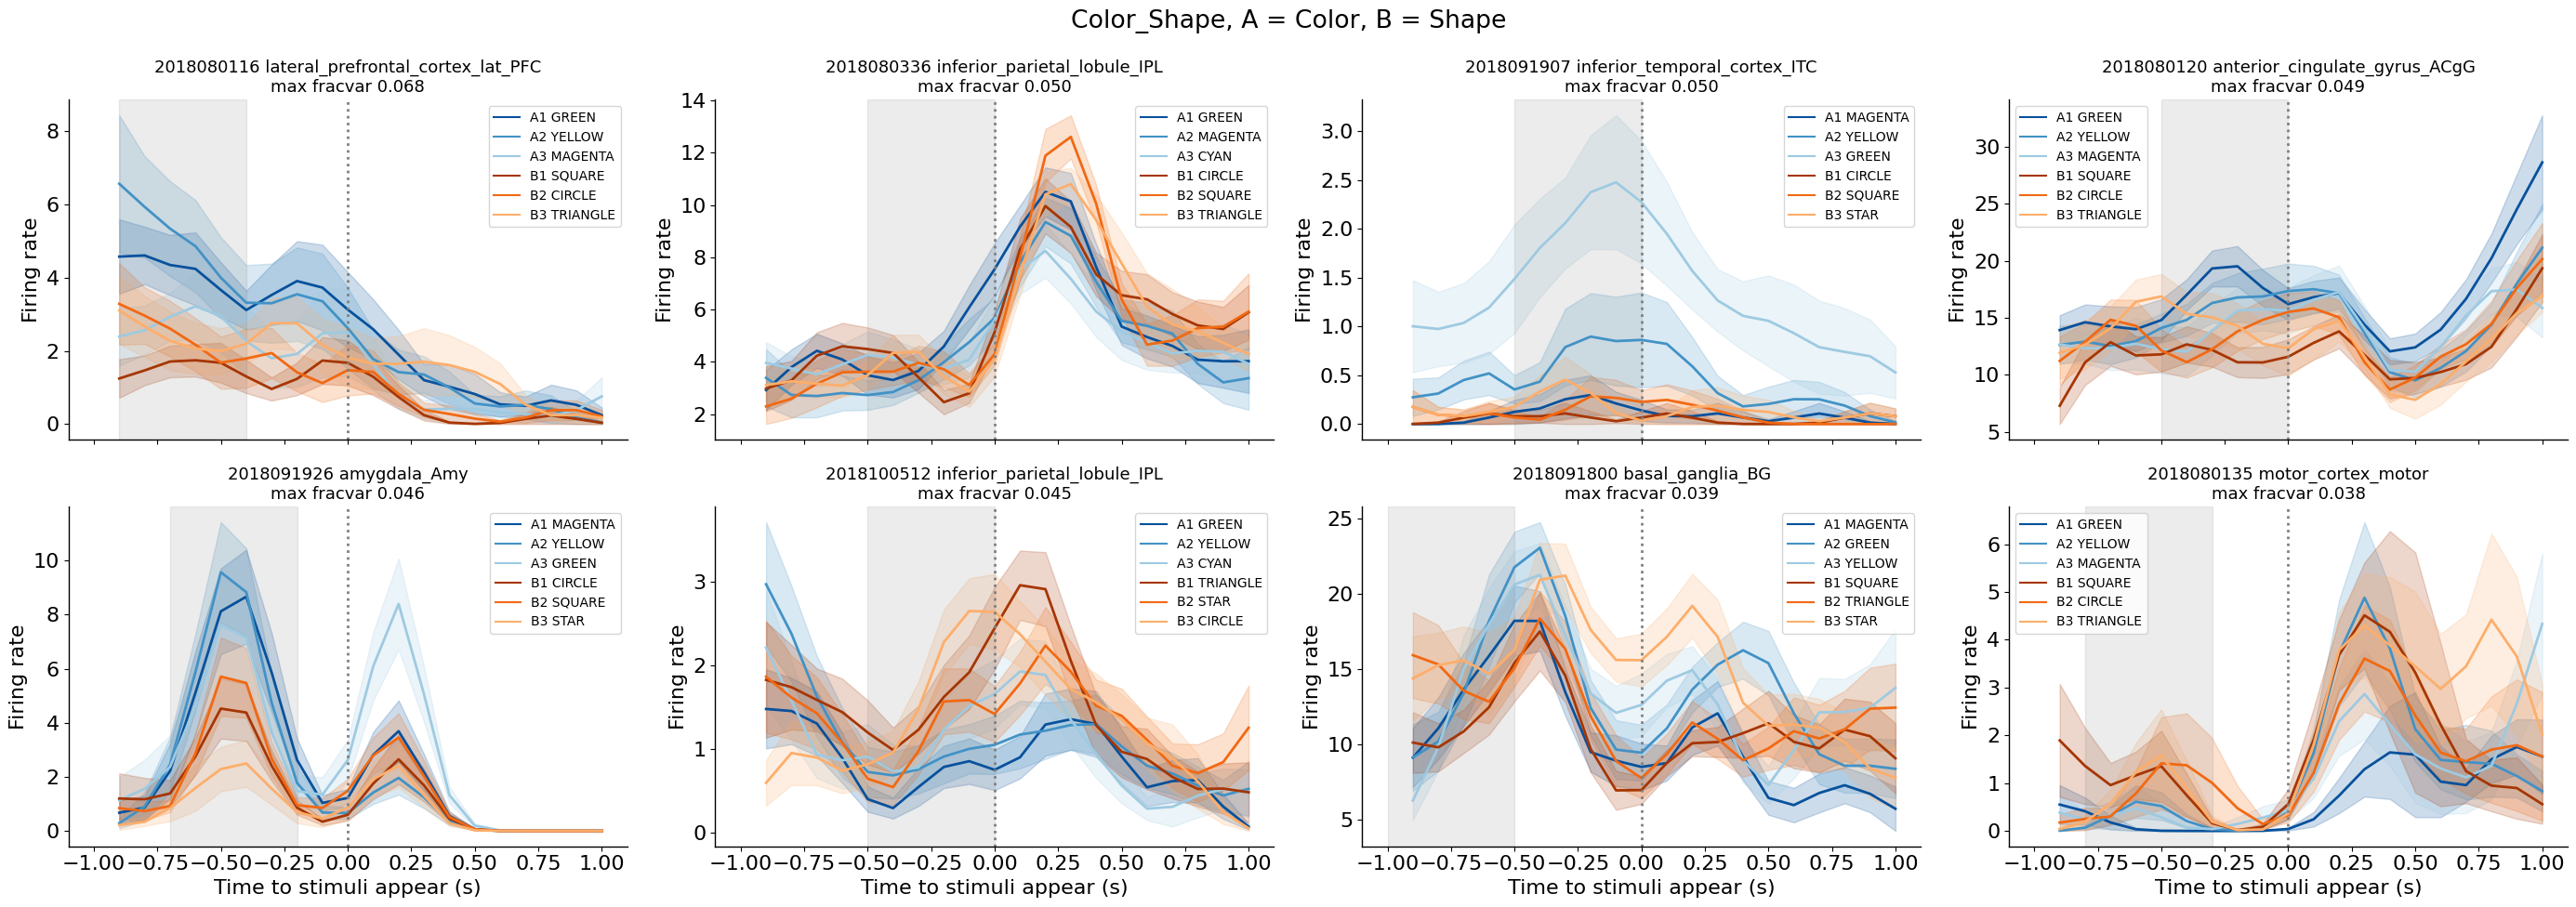

In [8]:
# PSTHs of the top dim pair units, ranked by their max x_Dimension_comb_time_fracvar over the
# dim_pair_anova.py windows. Per unit, the session's six features (assign_roles) and the balanced
# High trials the ANOVA used (select_balanced, same seed)
import utils.behavioral_utils as behavioral_utils
from constants.behavioral_constants import FEATURE_TO_DIM
from constants.decoding_constants import SIG_UNITS_PATH, SESS_SPIKES_PATH, get_trial_interval
from scripts.anova_analysis.dim_pair_anova import OUTPUT_PATH, RUN_NAME, SIG_LEVEL, select_balanced
from scripts.pseudo_decoding.belief_partitions.dim_ccgp_heldout_feat_beliefs import assign_roles

N_TOP_UNITS = 8
trial_interval = get_trial_interval("StimOnset")

stats = []
for sub in ["SA", "BL"]:
    sig_units = pd.read_pickle(SIG_UNITS_PATH.format(sub=sub, event="StimOnset", level=SIG_LEVEL))
    for _, row in dim_pairs.iterrows():
        dim_pair = f"{row.dim_a}_{row.dim_b}"
        anova = pd.read_pickle(os.path.join(OUTPUT_PATH, RUN_NAME.format(sub=sub), f"{dim_pair}.pickle"))
        anova = anova[anova.PseudoUnitID.isin(sig_units[sig_units.dim_pair == dim_pair].PseudoUnitID)]
        best = anova.loc[anova.groupby("PseudoUnitID").x_Dimension_comb_time_fracvar.idxmax()]
        best = pd.merge(best, sig_units[sig_units.dim_pair == dim_pair][["PseudoUnitID", "structure_level2_cleaned"]], on="PseudoUnitID")
        best["subject"], best["dim_a"], best["dim_b"] = sub, row.dim_a, row.dim_b
        stats.append(best.drop(columns="shuffle_fracvars"))
stats = pd.concat(stats, ignore_index=True)
top_units = stats.sort_values("x_Dimension_comb_time_fracvar", ascending=False).groupby("dim_pair").head(N_TOP_UNITS)


def unit_psth(row):
    """
    Firing rates of a unit on the ANOVA's balanced High trials of its session's six features,
    with feature, role, and Time (bin end, relative to StimOnset, as in the decoding plots)
    """
    sess_name = str(row.session)
    args = argparse.Namespace(**BeliefPartitionConfigs()._asdict())
    args.subject, args.dim_a, args.dim_b = row.subject, row.dim_a, row.dim_b
    beh = behavioral_utils.get_valid_belief_beh_for_sub_sess(row.subject, sess_name)
    feat_to_role = {f: role for role, f in assign_roles(beh, sess_name, args).items()}
    feat_to_dim = {f: FEATURE_TO_DIM[f] for f in feat_to_role}
    rng = np.random.default_rng([args.train_test_seed, int(sess_name), 0])
    trials, _, _ = select_balanced(beh, feat_to_dim, args.dim_a, rng)

    frs = pd.read_pickle(SESS_SPIKES_PATH.format(
        sub=row.subject, sess_name=sess_name, fr_type=args.fr_type, pre_interval=trial_interval.pre_interval,
        event=trial_interval.event, post_interval=trial_interval.post_interval, interval_size=trial_interval.interval_size,
    ))
    frs = frs[(frs.UnitID == row.PseudoUnitID % 100) & frs.TrialNumber.isin(trials)]
    frs = pd.merge(frs, beh[["TrialNumber", "PreferredBelief"]], on="TrialNumber")
    frs["Time"] = (frs.TimeBins * 1000 + trial_interval.interval_size - trial_interval.pre_interval) / 1000
    frs["role"] = frs.PreferredBelief.map(feat_to_role)
    frs["feature"] = frs.role + " " + frs.PreferredBelief
    return frs


# one color family per dimension: A roles blue, B roles orange
ROLE_TO_COLOR = {"A1": "#08519c", "A2": "#4292c6", "A3": "#9ecae1", "B1": "#a63603", "B2": "#f16913", "B3": "#fdae6b"}
for dim_pair, pair_units in top_units.groupby("dim_pair", sort=False):
    fig, axs = plt.subplots(2, N_TOP_UNITS // 2, figsize=(28, 10), sharex=True)
    for ax, (_, row) in zip(axs.flat, pair_units.iterrows()):
        frs = unit_psth(row)
        hue_order = sorted(frs.feature.unique())
        sns.lineplot(
            frs, x="Time", y="FiringRate", hue="feature", hue_order=hue_order,
            palette={f: ROLE_TO_COLOR[f.split(" ")[0]] for f in hue_order}, linewidth=2, errorbar="se", ax=ax,
        )
        ax.axvline(0, color="grey", linestyle="dotted", linewidth=2)
        # window of the unit's max fracvar, bins ending in (start, end]
        ax.axvspan(row.WindowStartMilli / 1000, row.WindowEndMilli / 1000, color="grey", alpha=0.15)
        ax.set_title(f"{row.PseudoUnitID} {row.structure_level2_cleaned}\nmax fracvar {row.x_Dimension_comb_time_fracvar:.3f}", fontsize=13)
        ax.set_xlabel("Time to stimuli appear (s)")
        ax.set_ylabel("Firing rate")
        ax.legend(fontsize=10, title=None)
    fig.suptitle(f"{dim_pair}, A = {pair_units.dim_a.iloc[0]}, B = {pair_units.dim_b.iloc[0]}")
    visualization_utils.format_plot(list(axs.flat))
    fig.tight_layout()